In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [2]:
DATA_PATH = Path("../data/raw/Telco-Customer-Churn.csv")
df = pd.read_csv(DATA_PATH)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training:", X_train.shape, "| Testing:", X_test.shape)

Training: (5634, 19) | Testing: (1409, 19)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
categorical_cols.append("SeniorCitizen")

In [4]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [5]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, numerical_cols),
    ("cat", cat_pipe, categorical_cols)
])

print("Preprocessor created successfully.")
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

Preprocessor created successfully.
Numerical features: 3
Categorical features: 16


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1
    ),
    "SVM": SVC(class_weight="balanced", probability=True, random_state=42)
}

print("Models prepared:", list(models.keys()))

Models prepared: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM']


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Cross-validation folds:", cv.get_n_splits())
print("Evaluation metrics:", list(scoring.keys()))

Cross-validation folds: 5
Evaluation metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


In [8]:
from sklearn.base import clone

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    results.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring}
    })

results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
display(results_df.round(4))

,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.7488,0.5174,0.8013,0.6286,0.8460
3,SVM,0.7504,0.5197,0.7799,0.6236,0.8267
2,Random Forest,0.7774,0.5712,0.6468,0.6065,0.8237
1,Decision Tree,0.7430,0.5159,0.5037,0.5096,0.6668


In [9]:
best_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", clone(models["Logistic Regression"]))
])

best_model.fit(X_train, y_train)

print("Selected model trained successfully.")

Selected model trained successfully.


In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Accuracy: 0.7374
Precision: 0.5034
Recall: 0.7834
F1-score: 0.613
ROC-AUC: 0.8414


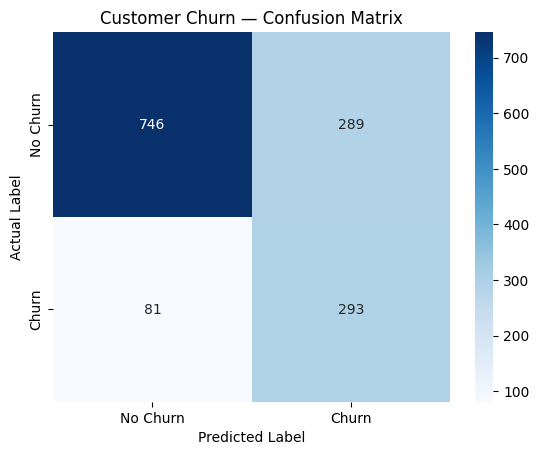

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Customer Churn — Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

In [13]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "churn_pipeline.joblib"
joblib.dump(best_model, model_path)

print("Model saved to:", model_path)

Model saved to: ..\models\churn_pipeline.joblib


In [14]:
loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn probability:", round(probability, 4))

Prediction: No Churn
Churn probability: 0.1154
